# 00 — Data checkout

Vue d'ensemble des données de délinéation : combien on en a, par rater, par groupe, par scan,
et ce qui a été gardé ou exclu par `02_easy_clean.py`.

**Entrées** (lecture seule) : `RESULTS/01_inventory.csv`, `RESULTS/02_easy_clean.csv`,
`DATA/DELINEATION_DATA` (dossiers raters).
À relancer après `01_inventory.py` et `02_easy_clean.py --apply`.

In [1]:
import csv
import sys
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Le notebook tourne depuis ANALYSIS/ ou depuis la racine du projet
ROOT = Path.cwd().parent if (Path.cwd() / "checks.py").exists() else Path.cwd()
sys.path.insert(0, str(ROOT / "ANALYSIS"))
import checks

RAW = ROOT / "DATA" / "DELINEATION_DATA"
CLEAN = ROOT / "DATA" / "CLEAN_DELINEATION"

def read_csv(name):
    with open(ROOT / "RESULTS" / name, encoding="utf-8-sig") as f:
        return list(csv.DictReader(f))

inventory = read_csv("01_inventory.csv")   # une ligne par fichier brut
clean_log = read_csv("02_easy_clean.csv")  # gardé / exclu + raison

# Hypothèse (non confirmée, comme dans le viewer) : label i = i-ème noyau de colors.md
NUCLEI = ["LGN", "MGN", "Pulvinar", "AV", "VA", "VLA/VLP", "VPL", "MD", "CM"]
C_HC, C_G = "#2a6fdb", "#e8833a"      # contrôle sain / glaucome
C_OK, C_BAD = "#3a9d5d", "#c0392b"    # gardé / exclu

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

def group_num(g):
    return int(g.split()[-1])

def cohort(scan):
    return "HC" if scan.startswith("SUBC") else "Glaucome" if scan.startswith("SUBG") else "?"

## 1. Vue d'ensemble

In [2]:
# Tous les dossiers rater (y compris vides = travail non rendu)
rater_files = {}   # (groupe, rater) -> nb de fichiers bruts
for gdir in RAW.iterdir():
    if gdir.is_dir():
        for rdir in gdir.iterdir():
            if rdir.is_dir():
                rater_files[(gdir.name, rdir.name.replace("Rater ", ""))] = sum(1 for p in rdir.iterdir() if p.is_file())

kept = [r for r in clean_log if r["status"] == "gardé"]
excluded = [r for r in clean_log if r["status"] == "exclu"]

# Scan de chaque fichier propre (nom déjà normalisé par 02)
clean_rows = []
for r in kept:
    group, rater_dir, fname = Path(r["new_file"].replace("\\", "/")).parts
    clean_rows.append({"group": group, "rater": rater_dir.replace("Rater ", ""),
                       "scan": checks.scan_key(fname), "path": CLEAN / r["new_file"].replace("\\", "/")})

raw_scans = {r["scan"] for r in inventory if r["scan"] and "?" not in r["scan"]}
clean_scans = {r["scan"] for r in clean_rows}

print(f"Groupes                    : {len({g for g, _ in rater_files})}")
print(f"Raters (dossiers)          : {len(rater_files)}  dont {sum(n == 0 for n in rater_files.values())} vides (non rendu)")
print(f"Fichiers bruts             : {len(inventory)}  ({sum(r['all_ok'] == 'True' for r in inventory)} passent les 5 tests sans correction)")
print(f"Après 02_easy_clean        : {len(kept)} gardés, {len(excluded)} exclus")
print(f"Scans distincts (bruts)    : {len(raw_scans)}")
print(f"Scans distincts (propres)  : {len(clean_scans)}  -> HC {sum(cohort(s) == 'HC' for s in clean_scans)}, "
      f"glaucome {sum(cohort(s) == 'Glaucome' for s in clean_scans)}")

Groupes                    : 16
Raters (dossiers)          : 167  dont 86 vides (non rendu)
Fichiers bruts             : 440  (220 passent les 5 tests sans correction)
Après 02_easy_clean        : 373 gardés, 67 exclus
Scans distincts (bruts)    : 116
Scans distincts (propres)  : 109  -> HC 87, glaucome 22


## 2. Rendu des raters
Combien de fichiers chaque rater a rendu (0 = dossier vide), et combien sont exploitables après nettoyage.

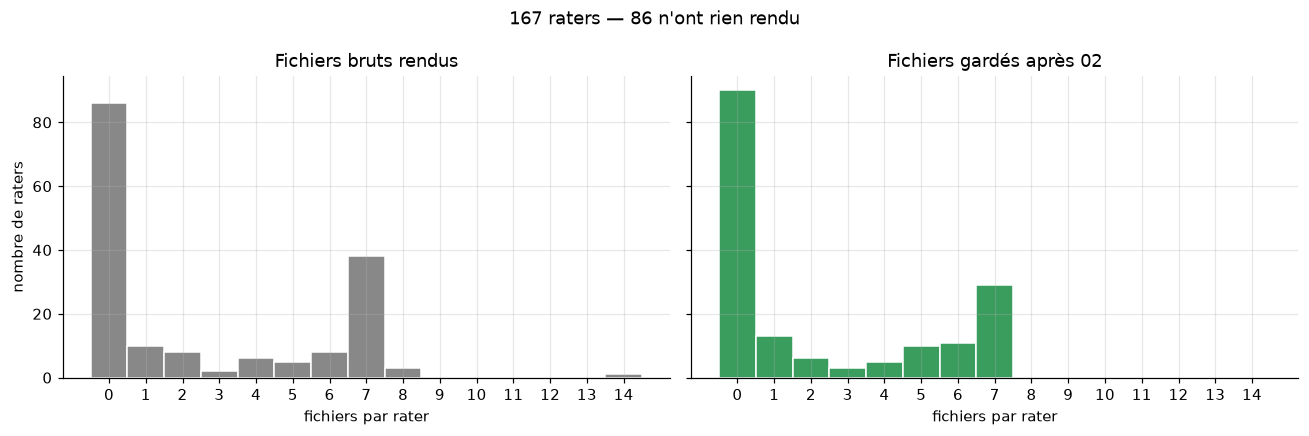

In [3]:
kept_per_rater = Counter((r["group"], r["rater"]) for r in clean_rows)
n_raw = np.array(list(rater_files.values()))
n_kept = np.array([kept_per_rater.get(k, 0) for k in rater_files])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
bins = np.arange(0, max(n_raw.max(), n_kept.max()) + 2) - 0.5
for ax, vals, title, color in [(axes[0], n_raw, "Fichiers bruts rendus", "#888"),
                               (axes[1], n_kept, "Fichiers gardés après 02", C_OK)]:
    ax.hist(vals, bins=bins, color=color, edgecolor="white")
    ax.set_title(title)
    ax.set_xlabel("fichiers par rater")
    ax.set_xticks(range(int(bins[-1]) + 1))
axes[0].set_ylabel("nombre de raters")
fig.suptitle(f"{len(rater_files)} raters — {int((n_raw == 0).sum())} n'ont rien rendu")
plt.tight_layout(); plt.show()

## 3. Par groupe
Fichiers gardés / exclus et raters sans rendu, groupe par groupe.

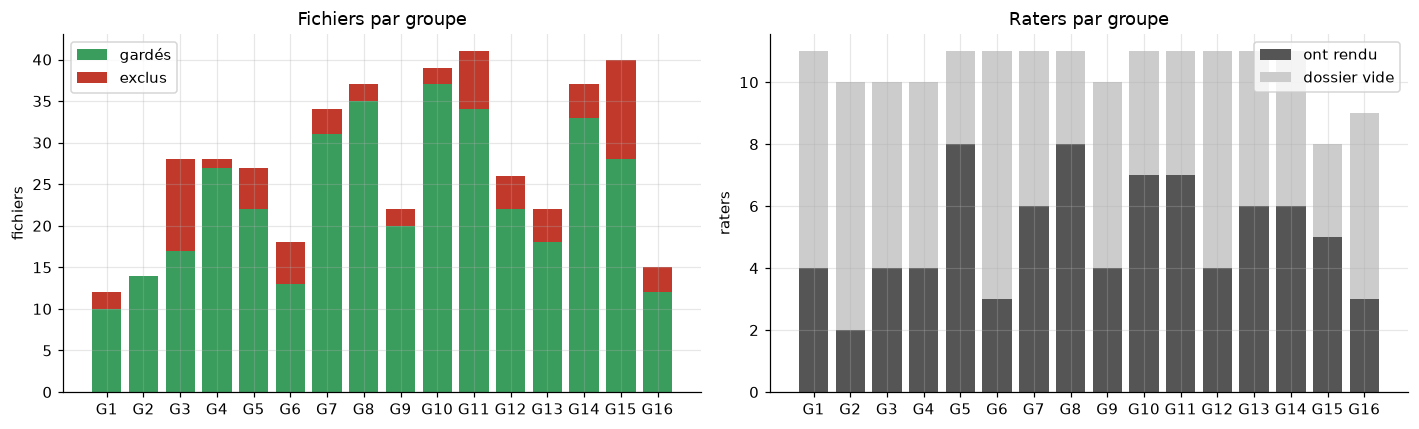

In [4]:
groups = sorted({g for g, _ in rater_files}, key=group_num)
g_kept = Counter(r["group"] for r in clean_rows)
g_excl = Counter(Path(r["original"].replace("\\", "/")).parts[0] for r in excluded)
g_empty = Counter(g for (g, _), n in rater_files.items() if n == 0)
g_raters = Counter(g for g, _ in rater_files)

x = np.arange(len(groups)); labels = [g.replace("Group ", "G") for g in groups]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
k = [g_kept[g] for g in groups]; e = [g_excl[g] for g in groups]
axes[0].bar(x, k, color=C_OK, label="gardés")
axes[0].bar(x, e, bottom=k, color=C_BAD, label="exclus")
axes[0].set_xticks(x, labels); axes[0].set_ylabel("fichiers"); axes[0].set_title("Fichiers par groupe"); axes[0].legend()

r_ok = [g_raters[g] - g_empty[g] for g in groups]; r_empty = [g_empty[g] for g in groups]
axes[1].bar(x, r_ok, color="#555", label="ont rendu")
axes[1].bar(x, r_empty, bottom=r_ok, color="#ccc", label="dossier vide")
axes[1].set_xticks(x, labels); axes[1].set_ylabel("raters"); axes[1].set_title("Raters par groupe"); axes[1].legend()
plt.tight_layout(); plt.show()

## 4. Problèmes détectés et exclusions
À gauche : nombre de fichiers bruts qui échouent à chaque test de `checks.py` (un fichier peut en échouer plusieurs).
À droite : pourquoi les fichiers exclus l'ont été. Les *copies exactes* ne sont pas une perte : une copie est gardée.

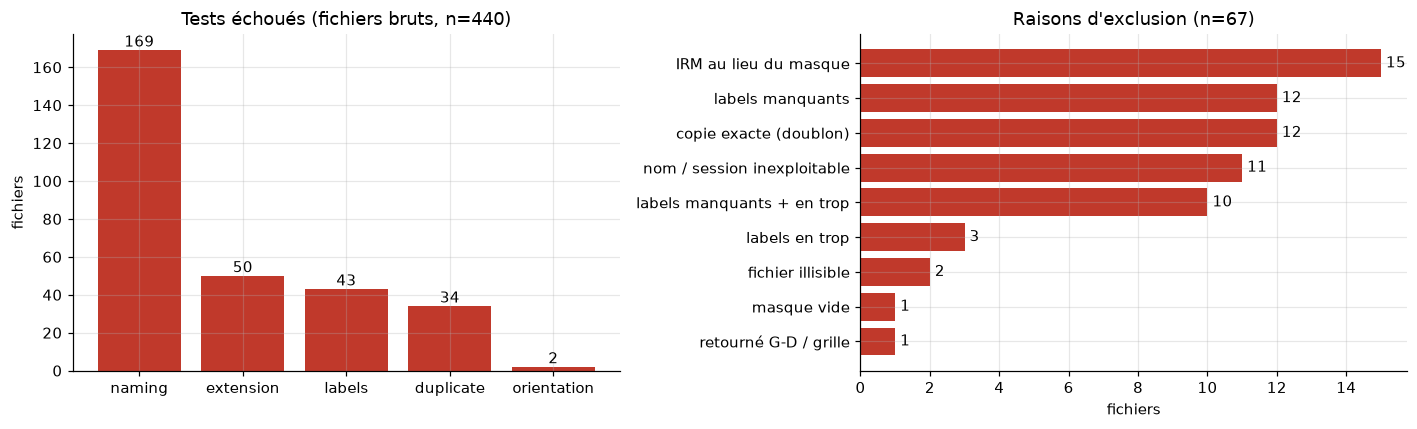

Labels manquants (nb de fichiers) : {'1 LGN': 3, '2 MGN': 4, '3 Pulvinar': 5, '4 AV': 3, '5 VA': 2, '6 VLA/VLP': 2, '7 VPL': 11, '8 MD': 11, '9 CM': 9}


In [5]:
fails = {p: sum(r[f"{p}_ok"] == "False" for r in inventory) for p in checks.PROBLEMS}

def reason_category(reason):
    kind, _, detail = reason.partition(":")
    detail = detail.strip()
    if kind == "labels":
        if "IRM" in detail: return "IRM au lieu du masque"
        if "vide" in detail: return "masque vide"
        if "illisible" in detail: return "fichier illisible"
        if "manquants" in detail and "en trop" in detail: return "labels manquants + en trop"
        if "manquants" in detail: return "labels manquants"
        return "labels en trop"
    if kind == "duplicate":
        return "copie exacte (doublon)" if "copie exacte" in detail else "doublons différents"
    if kind == "naming": return "nom / session inexploitable"
    if kind == "orientation": return "retourné G-D / grille"
    return kind
reasons = Counter(reason_category(r["reason"]) for r in excluded)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(list(fails), list(fails.values()), color="#c0392b")
for i, v in enumerate(fails.values()): axes[0].text(i, v, str(v), ha="center", va="bottom")
axes[0].set_title(f"Tests échoués (fichiers bruts, n={len(inventory)})"); axes[0].set_ylabel("fichiers")

items = reasons.most_common()[::-1]
axes[1].barh([k for k, _ in items], [v for _, v in items], color="#c0392b")
for i, (_, v) in enumerate(items): axes[1].text(v, i, f" {v}", va="center")
axes[1].set_title(f"Raisons d'exclusion (n={len(excluded)})"); axes[1].set_xlabel("fichiers")
plt.tight_layout(); plt.show()

# Quels labels manquent le plus souvent ?
missing = Counter()
for r in inventory:
    d = r["labels_detail"]
    if "manquants" in d:
        part = d.split("manquants")[1].split(";")[0]
        missing.update(int(t) for t in part.split() if t.isdigit())
print("Labels manquants (nb de fichiers) :", {f"{l} {NUCLEI[l-1]}": missing[l] for l in range(1, 10) if missing[l]})

## 5. Délinéations par scan
Combien de raters ont délinéé chaque scan. STAPLE (`03_staple.py`) demande **au moins 3** délinéations propres.

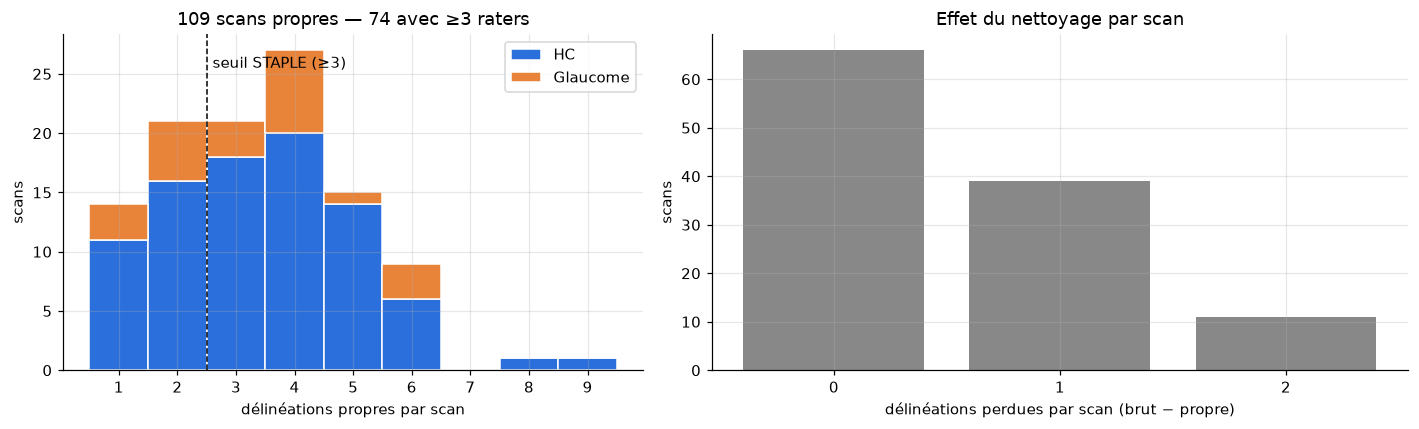

Scans perdus entièrement : ['SUBC009_ses9', 'SUBC042_ses3', 'SUBC043_ses4', 'SUBC045_ses5', 'SUBC047_ses6', 'SUBC048_ses7', 'SUBG001_ses2']


In [6]:
raw_per_scan = Counter(r["scan"] for r in inventory if r["scan"] and "?" not in r["scan"])
clean_per_scan = Counter(r["scan"] for r in clean_rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 1.2]})
m = max(raw_per_scan.values())
bins = np.arange(1, m + 2) - 0.5
hc = [n for s, n in clean_per_scan.items() if cohort(s) == "HC"]
gl = [n for s, n in clean_per_scan.items() if cohort(s) == "Glaucome"]
axes[0].hist([hc, gl], bins=bins, stacked=True, color=[C_HC, C_G], label=["HC", "Glaucome"], edgecolor="white")
axes[0].axvline(2.5, color="k", ls="--", lw=1); axes[0].text(2.6, axes[0].get_ylim()[1] * 0.9, "seuil STAPLE (≥3)")
axes[0].set_xticks(range(1, m + 1)); axes[0].set_xlabel("délinéations propres par scan"); axes[0].set_ylabel("scans")
axes[0].set_title(f"{len(clean_per_scan)} scans propres — {sum(n >= 3 for n in clean_per_scan.values())} avec ≥3 raters")
axes[0].legend()

# Brut vs propre : combien de délinéations perdues par scan
lost = Counter(raw_per_scan[s] - clean_per_scan.get(s, 0) for s in raw_per_scan)
axes[1].bar(list(lost), list(lost.values()), color="#888")
axes[1].set_xlabel("délinéations perdues par scan (brut − propre)"); axes[1].set_ylabel("scans")
axes[1].set_title("Effet du nettoyage par scan"); axes[1].set_xticks(sorted(lost))
plt.tight_layout(); plt.show()

print("Scans perdus entièrement :", sorted(set(raw_per_scan) - set(clean_per_scan)))

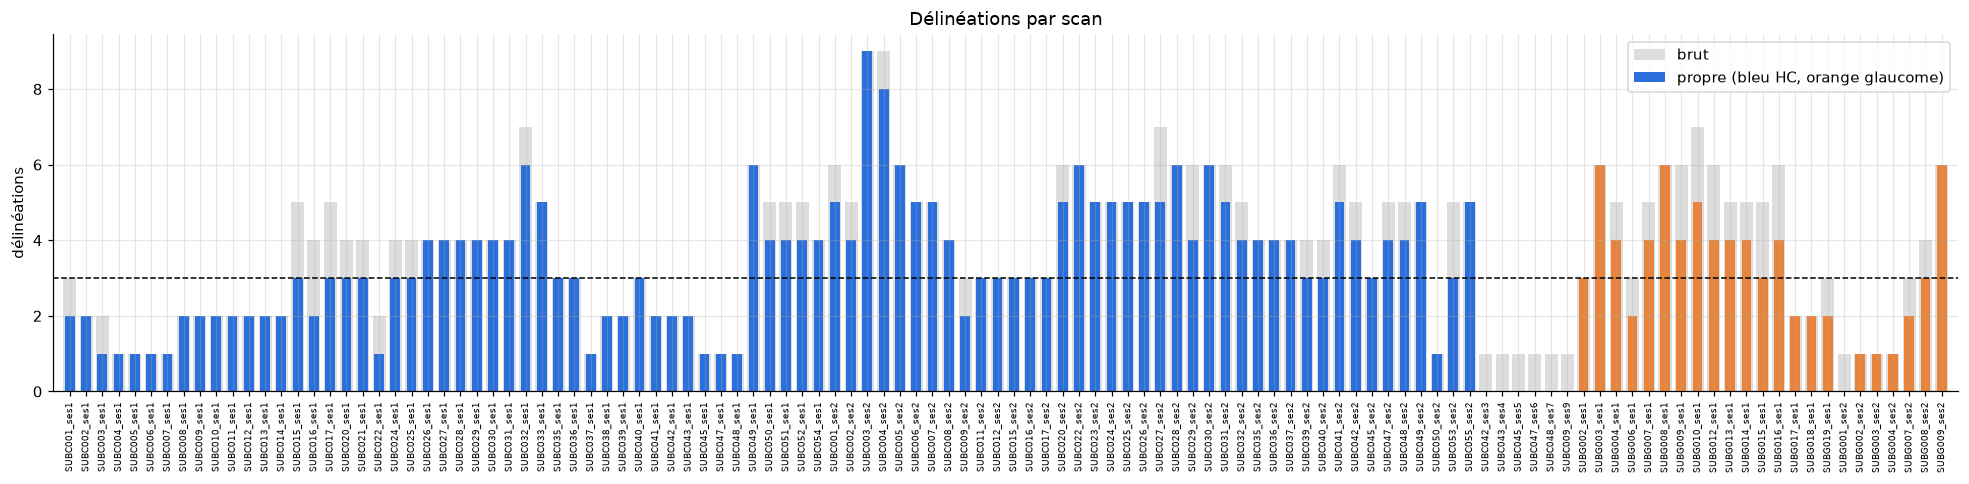

In [7]:
# Détail scan par scan (tri par cohorte, session, numéro)
scans = sorted(set(raw_per_scan) | set(clean_per_scan), key=lambda s: (s[3], s[-1], s))
fig, ax = plt.subplots(figsize=(18, 4.5))
x = np.arange(len(scans))
ax.bar(x, [raw_per_scan[s] for s in scans], color="#ddd", label="brut")
ax.bar(x, [clean_per_scan.get(s, 0) for s in scans], width=0.6,
       color=[C_HC if cohort(s) == "HC" else C_G for s in scans], label="propre (bleu HC, orange glaucome)")
ax.axhline(3, color="k", ls="--", lw=1)
ax.set_xticks(x, scans, rotation=90, fontsize=6); ax.set_xlim(-1, len(scans))
ax.set_ylabel("délinéations"); ax.set_title("Délinéations par scan"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

## 6. Composition des scans
Répartition contrôle sain / glaucome et session 1 / 2, en scans distincts et en délinéations.

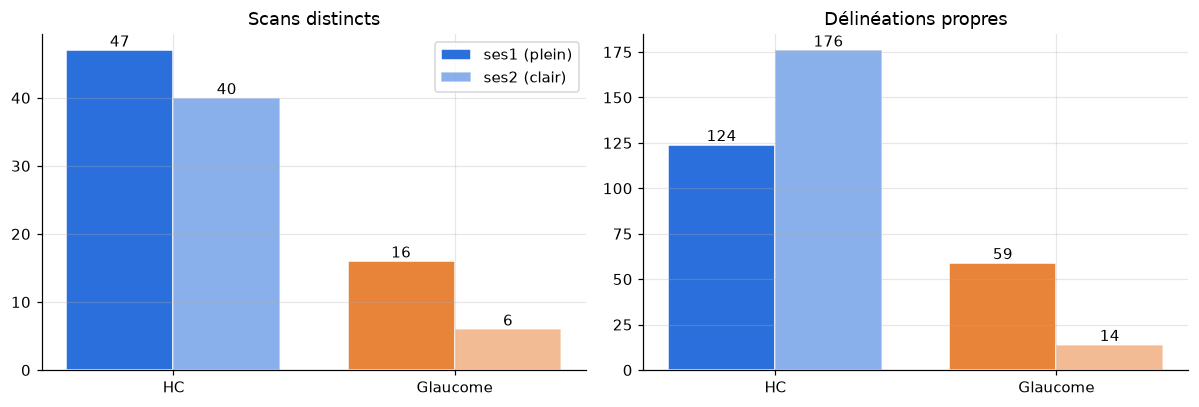

In [8]:
def session(scan): return "ses" + scan[-1]
combos = [(c, s) for c in ["HC", "Glaucome"] for s in ["ses1", "ses2"]]
n_scans = Counter((cohort(s), session(s)) for s in clean_per_scan)
n_delin = Counter((cohort(r["scan"]), session(r["scan"])) for r in clean_rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, cnt, title in [(axes[0], n_scans, "Scans distincts"), (axes[1], n_delin, "Délinéations propres")]:
    for j, ses in enumerate(["ses1", "ses2"]):
        vals = [cnt[(c, ses)] for c in ["HC", "Glaucome"]]
        bars = ax.bar(np.arange(2) + (j - 0.5) * 0.38, vals, width=0.38, label=ses,
                      color=[C_HC, C_G], alpha=1 if ses == "ses1" else 0.55, edgecolor="white")
        ax.bar_label(bars)
    ax.set_xticks([0, 1], ["HC", "Glaucome"]); ax.set_title(title)
axes[0].legend(["ses1 (plein)", "ses2 (clair)"])
plt.tight_layout(); plt.show()

## 7. Accord entre raters (Dice) et score par rater
Pour chaque scan avec au moins 2 délinéations propres, Dice entre chaque paire de raters
(moyenne des 9 noyaux ; 1 = identique, 0 = aucun recouvrement).
**Score d'un rater** = moyenne de ses Dice contre tous les autres raters de ses scans.
Lit chaque masque de `CLEAN_DELINEATION` (≈3 min).

In [11]:
from itertools import combinations

LABELS = range(1, 10)

def dice(a, b):
    s = a.sum() + b.sum()
    return 2 * np.logical_and(a, b).sum() / s if s else np.nan

masks_by_scan = defaultdict(list)
for r in clean_rows:
    masks_by_scan[r["scan"]].append(r)

pairs = []          # une ligne par paire de raters sur un même scan
mask_vol = {}       # (groupe, rater, scan) -> volume par noyau (mm³)
for scan, rows in masks_by_scan.items():
    datas = [np.asarray(checks.load(r["path"])[2]).astype(np.int16) for r in rows]
    for r, d in zip(rows, datas):
        mask_vol[(r["group"], r["rater"], scan)] = np.bincount(d.ravel(), minlength=10)[1:10]
    if len(rows) < 2:
        continue
    # recadrage sur la boîte qui contient tous les masques du scan (beaucoup plus rapide)
    nz = np.argwhere(np.any(np.stack([d > 0 for d in datas]), axis=0))
    lo, hi = nz.min(0), nz.max(0) + 1
    crops = [d[lo[0]:hi[0], lo[1]:hi[1], lo[2]:hi[2]] for d in datas]
    for (i, ri), (j, rj) in combinations(enumerate(rows), 2):
        per_label = [dice(crops[i] == l, crops[j] == l) for l in LABELS]
        pairs.append({"scan": scan, "a": (ri["group"], ri["rater"]), "b": (rj["group"], rj["rater"]),
                      "per_label": per_label, "dice": np.nanmean(per_label)})

print(f"{len(pairs)} paires sur {sum(len(v) >= 2 for v in masks_by_scan.values())} scans")
print(f"Dice moyen entre deux raters : {np.mean([p['dice'] for p in pairs]):.3f}")

595 paires sur 95 scans
Dice moyen entre deux raters : 0.576


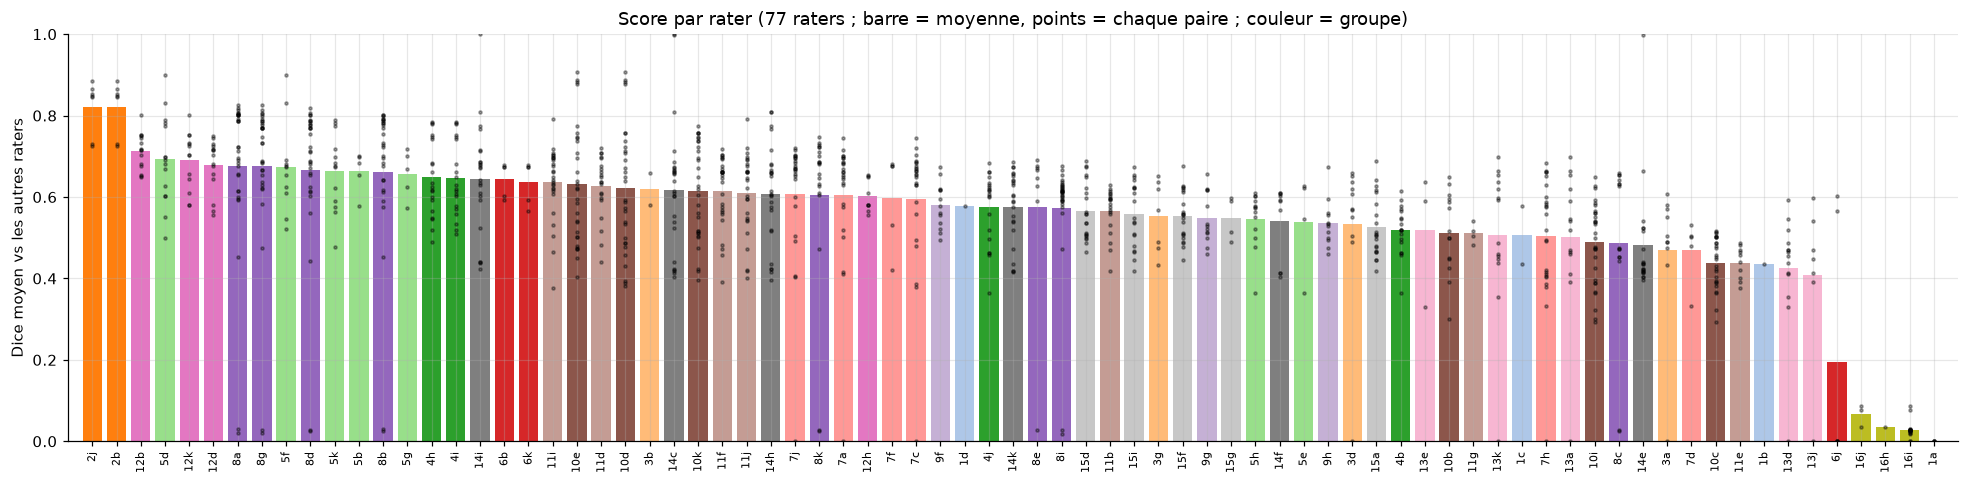

 rater  score  scans  paires
    1a  0.000      1       4
   16i  0.029      5      19
   16h  0.035      1       1
   16j  0.066      3       3
    6j  0.195      2       6
   13j  0.409      2       7
   13d  0.425      5      14
    1b  0.436      1       1
   11e  0.439      2      10
   10c  0.439      6      26
(10 plus bas — un score sur peu de paires est peu fiable)


In [12]:
# Score par rater
rater_dice = defaultdict(list)
rater_scans = defaultdict(set)
for p in pairs:
    for who in (p["a"], p["b"]):
        rater_dice[who].append(p["dice"])
        rater_scans[who].add(p["scan"])
scores = sorted(((np.mean(v), k, len(rater_scans[k]), len(v)) for k, v in rater_dice.items()), reverse=True)

fig, ax = plt.subplots(figsize=(18, 4.5))
x = np.arange(len(scores))
ax.bar(x, [s for s, *_ in scores], color=plt.cm.tab20(np.array([group_num(k[0]) for _, k, *_ in scores]) % 20))
for i, (_, k, *_) in enumerate(scores):   # points = chaque paire du rater
    v = rater_dice[k]
    ax.scatter(np.full(len(v), i), v, s=4, color="k", alpha=0.35, zorder=3)
ax.set_xticks(x, [k[1] for _, k, *_ in scores], rotation=90, fontsize=7); ax.set_xlim(-1, len(scores))
ax.set_ylim(0, 1); ax.set_ylabel("Dice moyen vs les autres raters")
ax.set_title(f"Score par rater ({len(scores)} raters ; barre = moyenne, points = chaque paire ; couleur = groupe)")
plt.tight_layout(); plt.show()

print(f"{'rater':>6} {'score':>6} {'scans':>6} {'paires':>7}")
for s, k, ns, npairs in scores[-10:][::-1]:
    print(f"{k[1]:>6} {s:6.3f} {ns:6d} {npairs:7d}")
print("(10 plus bas — un score sur peu de paires est peu fiable)")

## 8. Dice et volumes
**Volume relatif** d'un masque = son volume / volume médian des autres masques du même scan
(1 = comme les autres, > 1 = délinée plus gros, < 1 = plus petit).
Question : les raters avec un mauvais Dice délinéent-ils systématiquement trop gros ou trop petit ?
Et les petits noyaux ont-ils un Dice plus bas ?

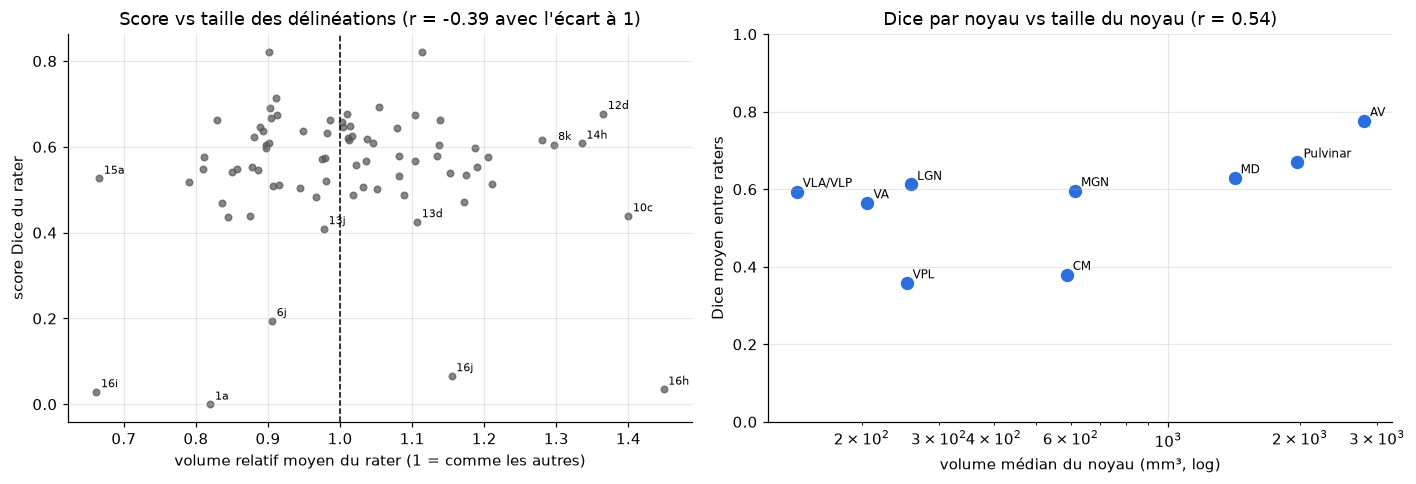

In [13]:
# Volume relatif de chaque masque (total thalamus), par rapport aux autres masques du même scan
rel = {}
for scan, rows in masks_by_scan.items():
    if len(rows) < 2:
        continue
    keys = [(r["group"], r["rater"], scan) for r in rows]
    for k in keys:
        others = [mask_vol[o].sum() for o in keys if o != k]
        rel[k] = mask_vol[k].sum() / np.median(others)

rater_rel = defaultdict(list)
for (g, r, scan), v in rel.items():
    rater_rel[(g, r)].append(v)

ks = [k for _, k, *_ in scores]
sc = np.array([s for s, *_ in scores])
rv = np.array([np.mean(rater_rel[k]) for k in ks])

# Dice et volume par noyau
label_dice = np.nanmean([p["per_label"] for p in pairs], axis=0)
label_vol = np.median(np.array(list(mask_vol.values())), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(rv, sc, s=18, alpha=0.7, color="#555")
axes[0].axvline(1, color="k", ls="--", lw=1)
r_ = np.corrcoef(np.abs(np.log(rv)), sc)[0, 1]
axes[0].set_xlabel("volume relatif moyen du rater (1 = comme les autres)"); axes[0].set_ylabel("score Dice du rater")
axes[0].set_title(f"Score vs taille des délinéations (r = {r_:.2f} avec l'écart à 1)")
for k, a, b in zip(ks, rv, sc):
    if b < np.percentile(sc, 8) or abs(np.log(a)) > 0.25:
        axes[0].annotate(k[1], (a, b), fontsize=7, xytext=(3, 3), textcoords="offset points")

axes[1].scatter(label_vol, label_dice, s=60, color="#2a6fdb")
for n, a, b in zip(NUCLEI, label_vol, label_dice):
    axes[1].annotate(n, (a, b), fontsize=8, xytext=(4, 3), textcoords="offset points")
axes[1].set_xscale("log"); axes[1].set_ylim(0, 1)
axes[1].set_xlabel("volume médian du noyau (mm³, log)"); axes[1].set_ylabel("Dice moyen entre raters")
axes[1].set_title(f"Dice par noyau vs taille du noyau (r = {np.corrcoef(np.log(label_vol), label_dice)[0, 1]:.2f})")
plt.tight_layout(); plt.show()

## 9. Nos délinéations (`DATA/completed_personal_delineation`)
Délinéations faites par l'équipe. Mêmes tests que `checks.py` (sauf le nommage, qui n'a pas le format `Rater`),
puis Dice de chacune contre les délinéations étudiantes propres du même scan.
Indépendant des sections 7–8.

In [ ]:
TEAM = ROOT / "DATA" / "completed_personal_delineation"

team = []
for p in sorted(TEAM.iterdir()):
    _, img, data = checks.load(p)
    lab_ok, lab_detail = checks.test_labels(data) if data is not None else (False, "illisible")
    team.append({"who": p.name.split("_")[2], "scan": checks.scan_key(p.name), "file": p.name,
                 "extension": checks.test_extension(p), "labels": (lab_ok, lab_detail),
                 "orientation": checks.test_orientation(img) if img is not None else (False, "illisible"),
                 "data": data})

students_per_scan = Counter(r["scan"] for r in clean_rows)
print(f"{len(team)} fichiers — " + ", ".join(f"{w} {n}" for w, n in Counter(t['who'] for t in team).most_common()))
print(f"\n{'qui':7} {'scan':13} {'extension':24} {'labels':22} {'orient.':8} raters étudiants")
for t in team:
    fmt = lambda ok_detail: "ok" if ok_detail[0] else ok_detail[1]
    print(f"{t['who']:7} {t['scan']:13} {fmt(t['extension']):24} {fmt(t['labels']):22} "
          f"{fmt(t['orientation']):8} {students_per_scan.get(t['scan'], 0)}")

In [ ]:
def dice_labels(a, b):
    """Dice moyen sur les noyaux 1–9 (un noyau absent d'un seul côté compte 0)."""
    out = []
    for l in range(1, 10):
        x, y = a == l, b == l
        s = x.sum() + y.sum()
        out.append(2 * np.logical_and(x, y).sum() / s if s else np.nan)
    return np.nanmean(out)

student_masks = defaultdict(list)
for r in clean_rows:
    if r["scan"] in {t["scan"] for t in team}:
        student_masks[r["scan"]].append((r["rater"], np.asarray(checks.load(r["path"])[2]).astype(np.int16)))

for t in team:
    mine = np.asarray(t["data"]).astype(np.int16)
    t["dice"] = [(rater, dice_labels(mine, m)) for rater, m in student_masks[t["scan"]]]

fig, ax = plt.subplots(figsize=(12, 4.5))
x = np.arange(len(team))
team_colors = {w: c for w, c in zip(sorted({t["who"] for t in team}), ["#2a6fdb", "#e8833a", "#3a9d5d", "#8e44ad"])}
ax.bar(x, [np.mean([d for _, d in t["dice"]]) if t["dice"] else 0 for t in team],
       color=[team_colors[t["who"]] for t in team], alpha=0.75)
for i, t in enumerate(team):
    for rater, d in t["dice"]:
        ax.scatter(i, d, s=14, color="k", zorder=3)
        ax.annotate(rater, (i, d), fontsize=6, xytext=(4, -2), textcoords="offset points")
ax.set_xticks(x, [f"{t['who']}\n{t['scan'].replace('_ses1', '')}" + ("\n⚠ labels" if not t["labels"][0] else "")
                  for t in team], fontsize=7)
ax.set_ylim(0, 1); ax.set_ylabel("Dice vs délinéations étudiantes")
ax.set_title("Nos délinéations vs celles des étudiants du même scan (barre = moyenne, points = chaque étudiant)")
plt.tight_layout(); plt.show()

alld = [d for t in team if t["labels"][0] for _, d in t["dice"]]
print(f"Dice moyen équipe vs étudiants (fichiers aux labels complets) : {np.mean(alld):.3f} sur {len(alld)} paires")